[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_12/MFM_ch12_btc_rnd/MFM_ch12_btc_rnd.ipynb)

# MFM_ch12_btc_rnd

Risk-neutral density of Bitcoin (Breeden-Litzenberger) from the Stochastic Volatility Inspired (SVI) smile of the expiry closest to 30 days, with a 95% pairs-bootstrap band and the range of quoted strikes, vs the log-normal density with the At the Money (ATM) volatility; tail probabilities with bootstrap intervals.

*Modelling Financial Markets (MFM), Chapter 12: Options and the Volatility Surface. Author: Daniel Traian Pele.*

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your ASE Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (CSV, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [1]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_12'
    os.makedirs(OUT_DIR, exist_ok=True)
    os.chdir(OUT_DIR)  # relative chart and CSV outputs persist in Drive
print('Save your outputs to:', os.path.abspath(OUT_DIR))


In [2]:
import os
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats, optimize, integrate
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')

N, n = stats.norm.cdf, stats.norm.pdf

Matplotlib is building the font cache; this may take a moment.


## Style and helpers

In [3]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Course colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
Teal     = '#17A2B8'

HERE = '.'
SEED = 42
BASE = {'S': 100.0, 'K': 100.0, 'T': 0.25, 'r': 0.04, 'sigma': 0.2}
HEDGE = {'S0': 100.0, 'K': 100.0, 'T': 0.25, 'r': 0.04, 'sigma': 0.2, 'mu': 0.08, 'nstep': 252, 'npath': 20000}


def save_fig(name):
    """Save the figure as PDF and transparent PNG in the current folder."""
    plt.savefig(f'{name}.pdf', bbox_inches='tight', transparent=True)
    plt.savefig(f'{name}.png', bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def fig_legend_bottom(fig, handles, ncol=3, y=0.0):
    """One legend for a multi-panel figure, below the figure."""
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def nw_mean(x, lags):
    """Mean and Newey-West (HAC) standard error of a series."""
    x = np.asarray(x, float)
    m = sm.OLS(x, np.ones_like(x)).fit(cov_type='HAC', cov_kwds={'maxlags': lags})
    return float(m.params[0]), float(m.bse[0])


def jsonable(o):
    if isinstance(o, dict):
        return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, np.ndarray)):
        return [jsonable(v) for v in o]
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    if isinstance(o, pd.Timestamp):
        return str(o)
    return o

## Data

In [4]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# course data: local copy when the notebook runs inside the repository, otherwise read online
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
SNAP_DIR = next((d for d in ('.', '../Quantlets/Ch_12', '../../Quantlets/Ch_12')
                 if os.path.exists(os.path.join(d, 'ch12_deribit_snapshot.csv'))), '.')
END = '2026-09-18'

# name -> (symbol, field, type)
SERIES = {
    'sp500': ('GSPC.INDX', 'close', 'index'),
    'spy':   ('SPY.US', 'adjusted_close', 'etf'),
    'btc':   ('BTC-USD.CC', 'close', 'crypto'),
    'vix':   ('VIX.INDX', 'close', 'vol'),
    'vix9d': ('VIX9D.INDX', 'close', 'vol'),
    'vix3m': ('VIX3M.INDX', 'close', 'vol'),
    'vvix':  ('VVIX.INDX', 'close', 'vol'),
}
DERIBIT = 'https://www.deribit.com/api/v2/public/'
SNAP_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/Quantlets/Ch_12/ch12_deribit_snapshot.csv'


def read_market(symbol):
    """Read the daily series of one symbol from the course data (local copy or online)."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def load_close(name, start=None, end=END):
    """Daily price (or index level); except for crypto assets, weekdays only
    (days with an unchanged close are kept: they are real trading days)."""
    symbol, col, kind = SERIES[name]
    s = read_market(symbol)[col].loc[start:end]
    s = s[s > 0].dropna()
    if kind != 'crypto':
        s = s[s.index.dayofweek < 5]
    return s.rename(name)


def log_returns(name, start=None, end=END):
    """Log returns on the series' own calendar."""
    return np.log(load_close(name, start, end)).diff().dropna().rename(name)


def spy_open_close(start=None, end=END):
    """Daily SPY open and close (unadjusted prices: the same-day ratio does not depend on adjustments)."""
    d = read_market('SPY.US').loc[start:end, ['open', 'close']]
    d = d[(d > 0).all(axis=1)]
    return d[d.index.dayofweek < 5]


def _get(method, **params):
    url = DERIBIT + method + '?' + '&'.join(f'{k}={v}' for k, v in params.items())
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    return json.load(urllib.request.urlopen(req, timeout=60))['result']


def deribit_chain(path=None, refresh=False):
    """BTC option chain (mark prices, implied volatilities) at the snapshot time."""
    path = path or os.path.join(SNAP_DIR, 'ch12_deribit_snapshot.csv')
    if not refresh:
        for src in (path, SNAP_RAW):
            try:
                return pd.read_csv(src, parse_dates=['snapshot_utc', 'expiry'])
            except Exception:
                pass
    rows = _get('get_book_summary_by_currency', currency='BTC', kind='option')
    t0 = pd.Timestamp.now(tz='UTC').floor('min').tz_localize(None)
    out = []
    for x in rows:
        _, exp, strike, cp = x['instrument_name'].split('-')
        out.append(dict(snapshot_utc=t0, instrument=x['instrument_name'],
                        expiry=pd.to_datetime(exp, format='%d%b%y') + pd.Timedelta(hours=8),
                        strike=float(strike), type='call' if cp == 'C' else 'put',
                        mark_iv=x['mark_iv'], mark_price=x['mark_price'], bid=x['bid_price'], ask=x['ask_price'],
                        forward=x['underlying_price'], index=x['estimated_delivery_price'],
                        open_interest=x['open_interest'], volume_usd=x['volume_usd']))
    d = pd.DataFrame(out).sort_values(['expiry', 'strike', 'type']).reset_index(drop=True)
    d.to_csv(path, index=False)
    return d


def dvol_history(start='2021-03-24', end=END):
    """DVOL index (30-day implied volatility of BTC options, annualised, in %), daily values."""
    t1 = int(pd.Timestamp(end).tz_localize('UTC').timestamp() * 1000) + 86_400_000
    t0 = int(pd.Timestamp(start).tz_localize('UTC').timestamp() * 1000)
    data = []
    while True:
        r = _get('get_volatility_index_data', currency='BTC', start_timestamp=t0, end_timestamp=t1, resolution='1D')
        data += r['data']
        if not r.get('continuation') or r['continuation'] <= t0:
            break
        t1 = r['continuation']
    d = pd.DataFrame(data, columns=['t', 'open', 'high', 'low', 'close']).drop_duplicates('t')
    d.index = pd.to_datetime(d['t'], unit='ms').dt.normalize()
    return d.sort_index()['close'].loc[start:end].rename('dvol')

## Option pricing tools

In [5]:
def bs_price(S, K, T, r, sigma, kind='call', q=0.0):
    """Black-Scholes price of a European option."""
    S, K, T, sigma = map(np.asarray, (S, K, T, sigma))
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if kind == 'call':
        return S * np.exp(-q * T) * N(d1) - K * np.exp(-r * T) * N(d2)
    return K * np.exp(-r * T) * N(-d2) - S * np.exp(-q * T) * N(-d1)


def bs_greeks(S, K, T, r, sigma, kind='call', q=0.0):
    """Delta, gamma, vega (per volatility point), theta (per calendar day), rho; plus d1, d2."""
    S, K, T, sigma = map(np.asarray, (S, K, T, sigma))
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    gamma = np.exp(-q * T) * n(d1) / (S * sigma * np.sqrt(T))
    vega = S * np.exp(-q * T) * n(d1) * np.sqrt(T) / 100
    common = -S * np.exp(-q * T) * n(d1) * sigma / (2 * np.sqrt(T))
    if kind == 'call':
        delta = np.exp(-q * T) * N(d1)
        theta = common - r * K * np.exp(-r * T) * N(d2) + q * S * np.exp(-q * T) * N(d1)
        rho = K * T * np.exp(-r * T) * N(d2) / 100
    else:
        delta = -np.exp(-q * T) * N(-d1)
        theta = common + r * K * np.exp(-r * T) * N(-d2) - q * S * np.exp(-q * T) * N(-d1)
        rho = -K * T * np.exp(-r * T) * N(-d2) / 100
    return dict(d1=d1, d2=d2, delta=delta, gamma=gamma, vega=vega, theta=theta / 365, rho=rho)


def implied_vol(price, S, K, T, r, kind='call', q=0.0, lo=1e-4, hi=5.0):
    """Implied volatility: the unique solution of BS(sigma) = price (vega > 0)."""
    f = lambda s: bs_price(S, K, T, r, s, kind, q) - price
    if f(lo) > 0 or f(hi) < 0:
        return np.nan
    return optimize.brentq(f, lo, hi, xtol=1e-10)


def newton_iv(price, S, K, T, r, sigma0=0.2, kind='call', steps=4):
    """Newton steps: sigma_{k+1} = sigma_k - (BS(sigma_k) - price) / vega(sigma_k)."""
    out, s = [], sigma0
    for _ in range(steps):
        p = float(bs_price(S, K, T, r, s, kind))
        v = float(bs_greeks(S, K, T, r, s, kind)['vega']) * 100
        s_new = s - (p - price) / v
        out.append(dict(sigma=s, price=p, vega=v, sigma_next=s_new))
        s = s_new
    return out


def crr_price(S, K, T, r, sigma, steps, kind='call', american=False):
    """Cox-Ross-Rubinstein binomial tree: u = exp(sigma sqrt(dt)), d = 1/u, p = (e^{r dt} - d)/(u - d)."""
    dt = T / steps
    u = np.exp(sigma * np.sqrt(dt)); d = 1 / u
    p = (np.exp(r * dt) - d) / (u - d)
    disc = np.exp(-r * dt)
    j = np.arange(steps + 1)
    ST = S * u ** (steps - j) * d ** j
    V = np.maximum(ST - K, 0) if kind == 'call' else np.maximum(K - ST, 0)
    for i in range(steps - 1, -1, -1):
        V = disc * (p * V[:-1] + (1 - p) * V[1:])
        if american:
            Si = S * u ** (i - np.arange(i + 1)) * d ** np.arange(i + 1)
            V = np.maximum(V, (Si - K) if kind == 'call' else (K - Si))
    return float(V[0])


def merton_price(S, K, T, r, sigma, lam, mu_j, sig_j, kind='call', nmax=60):
    """Merton (1976): log-normal jumps ln(1+J) ~ N(mu_j, sig_j^2), intensity lam; Poisson series of BS prices."""
    kappa = np.exp(mu_j + 0.5 * sig_j ** 2) - 1
    lam2 = lam * (1 + kappa)
    tot = 0.0
    for k in range(nmax):
        s_k = np.sqrt(sigma ** 2 + k * sig_j ** 2 / T)
        r_k = r - lam * kappa + k * np.log(1 + kappa) / T
        w = stats.poisson.pmf(k, lam2 * T)
        tot = tot + w * bs_price(S, K, T, r_k, s_k, kind)
    return tot


def heston_price(S, K, T, r, v0, kappa, theta, xi, rho, kind='call'):
    """Heston (1993): call price by the Lewis (2001) formula, with the characteristic function of ln(S_T/F) (stable form)."""
    def phi(u):
        d = np.sqrt((rho * xi * 1j * u - kappa) ** 2 + xi ** 2 * (1j * u + u ** 2))
        g = (kappa - rho * xi * 1j * u - d) / (kappa - rho * xi * 1j * u + d)
        e = np.exp(-d * T)
        C = kappa * theta / xi ** 2 * ((kappa - rho * xi * 1j * u - d) * T - 2 * np.log((1 - g * e) / (1 - g)))
        D = (kappa - rho * xi * 1j * u - d) / xi ** 2 * (1 - e) / (1 - g * e)
        return np.exp(C + D * v0)
    x = np.log(S / K) + r * T
    f = lambda u: (np.exp(1j * u * x) * phi(u - 0.5j)).real / (u ** 2 + 0.25)
    call = S - np.sqrt(S * K) * np.exp(-r * T / 2) / np.pi * integrate.quad(f, 0, 200, limit=500, epsabs=1e-12)[0]
    return call if kind == 'call' else call - S + K * np.exp(-r * T)


def svi_w(k, a, b, rho, m, s):
    """SVI (Gatheral): total implied variance w(k) = a + b (rho (k - m) + sqrt((k - m)^2 + s^2)), k = ln(K/F)."""
    return a + b * (rho * (k - m) + np.sqrt((k - m) ** 2 + s ** 2))


def svi_fit(k, w, weights=None):
    """SVI fit by (weighted) least squares, with constraints b >= 0, |rho| < 1, s > 0."""
    k, w = np.asarray(k), np.asarray(w)
    wt = np.ones_like(w) if weights is None else np.asarray(weights)
    def loss(p):
        return np.sum(wt * (svi_w(k, *p) - w) ** 2)
    best = None
    for rho0 in (-0.5, 0.0, 0.3):
        for s0 in (0.05, 0.2):
            x0 = [max(w.min() * 0.5, 1e-4), 0.1, rho0, 0.0, s0]
            res = optimize.minimize(loss, x0, method='L-BFGS-B',
                                    bounds=[(-1, 5), (1e-6, 10), (-0.999, 0.999), (-2, 2), (1e-4, 3)])
            if best is None or res.fun < best.fun:
                best = res
    a, b, rho, m, s = best.x
    return dict(a=a, b=b, rho=rho, m=m, s=s, rmse=np.sqrt(best.fun / wt.sum()),
                wmin=a + b * s * np.sqrt(1 - rho ** 2))


def variance_from_strip(K, Q, F, T, r=0.0):
    """Implied variance (VIX formula): 2/T sum dK/K^2 e^{rT} Q(K) - 1/T (F/K0 - 1)^2, Q = OTM price (mid)."""
    K, Q = np.asarray(K, float), np.asarray(Q, float)
    o = np.argsort(K); K, Q = K[o], Q[o]
    dK = np.empty_like(K)
    dK[1:-1] = (K[2:] - K[:-2]) / 2
    dK[0], dK[-1] = K[1] - K[0], K[-1] - K[-2]
    K0 = K[K <= F].max()
    return 2 / T * np.sum(dK / K ** 2 * np.exp(r * T) * Q) - (F / K0 - 1) ** 2 / T


def delta_hedge(paths, K, T, r, sigma_imp, n_rebal, kind='call'):
    """Sell an option at BS(sigma_imp) and delta-hedge it n_rebal times until expiry.
    paths: price matrix (n_paths, n_steps+1) on a uniform grid; n_steps divisible by n_rebal.
    Returns the hedging error at expiry (hedge portfolio value minus the option pay-off)."""
    npath, nstep = paths.shape[0], paths.shape[1] - 1
    every = nstep // n_rebal
    dt = T / nstep
    S0 = paths[:, 0]
    V0 = bs_price(S0, K, T, r, sigma_imp, kind)
    delta = bs_greeks(S0, K, T, r, sigma_imp, kind)['delta']
    cash = V0 - delta * S0
    for i in range(1, nstep + 1):
        cash = cash * np.exp(r * dt)
        if i % every == 0 and i < nstep:
            tau = T - i * dt
            d_new = bs_greeks(paths[:, i], K, tau, r, sigma_imp, kind)['delta']
            cash -= (d_new - delta) * paths[:, i]
            delta = d_new
    ST = paths[:, -1]
    payoff = np.maximum(ST - K, 0) if kind == 'call' else np.maximum(K - ST, 0)
    return cash + delta * ST - payoff

## Analysis

In [6]:
def btc_surface():
    """SVI fit for every expiry of the BTC chain (quoted OTM options, at least 2 days to expiry)."""
    c = deribit_chain()
    t0 = c['snapshot_utc'].iloc[0]
    c['T'] = (c['expiry'] - t0).dt.total_seconds() / (365 * 86400)
    c = c[(c['T'] >= 2 / 365) & (c['mark_iv'] > 0) & (c['bid'] > 0)]
    c = c[((c['type'] == 'put') & (c['strike'] < c['forward'])) | ((c['type'] == 'call') & (c['strike'] >= c['forward']))].copy()
    c['k'] = np.log(c['strike'] / c['forward'])
    c['w'] = (c['mark_iv'] / 100) ** 2 * c['T']
    c = c[c['k'].abs() < 1.2]
    fits = {}
    for e, g in c.groupby('expiry'):
        if len(g) < 7:
            continue
        f = svi_fit(g['k'].values, g['w'].values)
        T = g['T'].iloc[0]
        iv = lambda k: 100 * np.sqrt(svi_w(k, f['a'], f['b'], f['rho'], f['m'], f['s']) / T)
        fits[e] = dict(T=T, days=T * 365, F=float(g['forward'].iloc[0]), n=int(len(g)), atm=float(iv(0.0)),
                       rr=float(iv(0.15) - iv(-0.15)), wing_dn=float(iv(-0.3)), wing_up=float(iv(0.3)),
                       rmse_iv=float(np.sqrt(np.mean((iv(g['k'].values) - g['mark_iv'].values) ** 2))), **f)
    tab = pd.DataFrame(fits).T
    tab.index.name = 'expiry'
    tab.to_csv(os.path.join(HERE, 'ch12_btc_svi.csv'))
    return c, tab, t0


def pick(tab, days):
    """Expiry closest to a given number of days."""
    return (tab['days'] - days).abs().astype(float).idxmin()


def rnd_from_svi(p, F, T, K):
    """Risk-neutral density (Breeden-Litzenberger) from SVI parameters on the strike grid K."""
    k = np.log(K / F)
    sig = np.sqrt(np.clip(svi_w(k, *p), 1e-10, None) / T)
    C = bs_price(F, K, T, 0.0, sig, 'call')
    return np.clip(np.gradient(np.gradient(C, K), K), 0, None)


def btc_rnd(tab, c=None, days=30, B=300):
    """Risk-neutral density (Breeden-Litzenberger) from SVI for the expiry closest to 30 days;
    pairs-bootstrap band (SVI re-fitted on resampled quotes) and the range of observed quotes."""
    e = pick(tab, days); f = tab.loc[e]
    F, T = f['F'], f['T']
    p0 = [float(f[x]) for x in ['a', 'b', 'rho', 'm', 's']]
    K = F * np.exp(np.linspace(-1.2, 1.0, 2201))
    q = rnd_from_svi(p0, F, T, K)
    atm = np.sqrt(svi_w(0.0, *p0) / T)
    ln = stats.lognorm.pdf(K, s=atm * np.sqrt(T), scale=F * np.exp(-0.5 * atm ** 2 * T))
    area = integrate.trapezoid(q, K)
    below_q = lambda qq, x: float(integrate.trapezoid(qq[K <= x * F], K[K <= x * F]) / integrate.trapezoid(qq, K))
    below = lambda x: below_q(q, x)
    lnb = lambda x: float(stats.lognorm.cdf(x * F, s=atm * np.sqrt(T), scale=F * np.exp(-0.5 * atm ** 2 * T)))
    out = dict(expiry=str(pd.Timestamp(e).date()), days=float(f['days']), F=float(F), atm=float(100 * atm), area=float(area),
               p80=below(0.8), p120=1 - below(1.2), ln80=lnb(0.8), ln120=1 - lnb(1.2), p70=below(0.7), ln70=lnb(0.7))
    band = None
    if c is not None:
        g = c[c['expiry'] == e]
        kq, wq = g['k'].values, g['w'].values
        rng = np.random.default_rng(SEED)
        Q, P70, P80 = [], [], []
        while len(Q) < B:
            i = rng.integers(0, len(kq), len(kq))
            if len(np.unique(kq[i])) < 6:
                continue
            pb = svi_fit(kq[i], wq[i])
            qb = rnd_from_svi([pb[x] for x in ['a', 'b', 'rho', 'm', 's']], F, T, K)
            Q.append(qb); P70.append(below_q(qb, 0.7)); P80.append(below_q(qb, 0.8))
        Q = np.array(Q)
        band = (np.quantile(Q, 0.025, axis=0), np.quantile(Q, 0.975, axis=0))
        kmin, kmax = float(np.exp(kq.min())), float(np.exp(kq.max()))
        out.update(ext70=below(kmin), ext70_share=below(kmin) / out['p70'])   # mass below the last quote (SVI extrapolation)
        out.update(B=int(B), p70_lo=float(np.quantile(P70, 0.025)), p70_hi=float(np.quantile(P70, 0.975)),
                   p80_lo=float(np.quantile(P80, 0.025)), p80_hi=float(np.quantile(P80, 0.975)),
                   kf_min=kmin, kf_max=kmax, n_quotes=int(len(kq)),
                   width_centre=float((band[1] - band[0])[np.argmin(np.abs(K / F - 1))] / q[np.argmin(np.abs(K / F - 1))]),
                   width_070=float((band[1] - band[0])[np.argmin(np.abs(K / F - 0.7))] / max(q[np.argmin(np.abs(K / F - 0.7))], 1e-30)))
    fig, ax = plt.subplots(figsize=(7.0, 3.2))
    if band is not None:
        ax.fill_between(K / F, band[0] * F, band[1] * F, color=Teal, alpha=0.35, lw=0,
                        label=f'95% pairs-bootstrap band ({B} SVI refits)')
        ax.axvspan(0.3, out['kf_min'], color='#F5E6CC', alpha=0.7, lw=0,
                   label=f"Outside the quoted strikes ({out['kf_min']:.2f}F to {out['kf_max']:.2f}F): SVI extrapolation")
        ax.axvspan(out['kf_max'], 1.6, color='#F5E6CC', alpha=0.7, lw=0)
    ax.plot(K / F, q * F, color=MainBlue, lw=1.6, label='Risk-neutral density implied by the SVI smile')
    ax.plot(K / F, ln * F, color=Orange, lw=1.2, ls='--', label=f'Log-normal density with the ATM volatility ({100 * atm:.1f}%)')
    ax.set_xlim(0.4 if band is not None else 0.5, 1.6)
    ax.set_xlabel('$S_T/F$ at expiry'); ax.set_ylabel('Density')
    ax.set_title(f"Bitcoin, expiry {pd.Timestamp(e).strftime('%d %b %Y')} ({f['days']:.0f} days), forward {F:,.0f} USD",
                 fontsize=8.5, loc='left')
    legend_outside_bottom(ax, ncol=2 if band is not None else 1, y=-0.2)
    save_fig('ch12_btc_rnd')
    return out

## Run

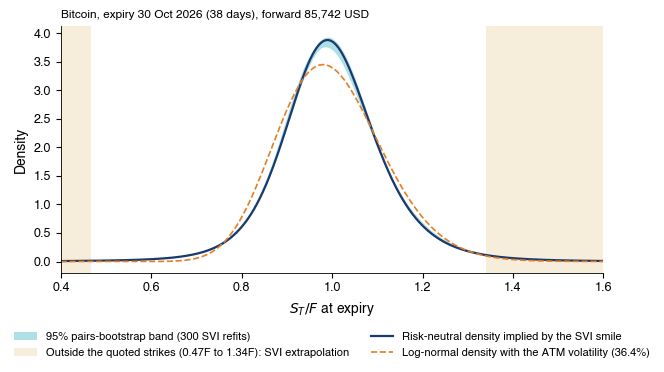

   saved ch12_btc_rnd


{'expiry': '2026-10-30',
 'days': 38.00625,
 'F': 85741.86,
 'atm': 36.37165153045735,
 'area': 0.999671921041769,
 'p80': 0.04281132662822667,
 'p120': 0.05328238761837101,
 'ln80': 0.03269582136723214,
 'ln120': 0.053467780979009505,
 'p70': 0.01206988333734691,
 'ln70': 0.0014398245934027362,
 'ext70': 0.001261706349662962,
 'ext70_share': 0.10453343370428124,
 'B': 300,
 'p70_lo': 0.010761157390222462,
 'p70_hi': 0.01244361642680597,
 'p80_lo': 0.04043215502353154,
 'p80_hi': 0.04455003874821819,
 'kf_min': 0.4665165882802169,
 'kf_max': 1.3412351913056237,
 'n_quotes': 56,
 'width_centre': 0.05075802774095489,
 'width_070': 0.16995038907797286}

In [7]:
c, tab, t0 = btc_surface()
btc_rnd(tab, c)

![ch12_btc_rnd](./ch12_btc_rnd.png)

Output: `ch12_btc_rnd.pdf`